In [1]:
import json

landslide_truth = [
    (121.3061635098438, 23.703992232549655, "Y"),
    (121.30731649919981, 23.70373198228068, "Y"),
    (121.30650331946988, 23.7032225700078, "Y"),
    (121.30742306972793, 23.702838894216715, "Y"),
    (121.30634639941334, 23.702475827189748, "Y"),
    (121.30753583100906, 23.702502138634376, "Y"),
    (121.30624920756094, 23.70205447975377, "Y"),
    (121.30732837110972, 23.702009254523936, "Y"),
    (121.30641365193624, 23.701563990112135, "Y"),
    (121.30648876143486, 23.701073039701075, "Y"),
]

stable_truth = [
    (121.3141492544933, 23.70105738662312, 'N'),
    (121.31499265345711, 23.70103790633488, 'N'),
    (121.31407994569585, 23.699803581003007, 'N'),
    (121.315352615308,   23.69998080517178, 'N'),
    (121.31383909560971, 23.698995429840817, 'N'),
    (121.31530763248944, 23.69898604025192, 'N'),
    (121.31403719438201, 23.698189553880898, 'N'),
    (121.31400041408163, 23.69730612879972, 'N'),
    (121.31516205836908, 23.696998732276644, 'N'),
    (121.31261645662217, 23.697070975314183, 'N')
]

def convert_truth_label(label):
    if label == "Y":
        return "landslide"
    elif label == "N":
        return "stable"
    else:
        return "unknown"

def make_feature(lon, lat, label, source="field_corrected"):
    return {
        "type": "Feature",
        "properties": {
            "lon": lon,
            "lat": lat,
            "truth": convert_truth_label(label),
            "source": source
        },
        "geometry": {
            "type": "Point",
            "coordinates": [lon, lat]
        }
    }

all_points = landslide_truth + stable_truth

geojson = {
    "type": "FeatureCollection",
    "name": "validation_points",
    "crs": {
        "type": "name",
        "properties": {
            "name": "urn:ogc:def:crs:OGC:1.3:CRS84"
        }
    },
    "features": [make_feature(lon, lat, label) for lon, lat, label in all_points]
}

# 印出結果
print(json.dumps(geojson, indent=2, ensure_ascii=False))

# 如果要存成檔案
with open("my_validation_points.geojson", "w", encoding="utf-8") as f:
    json.dump(geojson, f, indent=2, ensure_ascii=False)

{
  "type": "FeatureCollection",
  "name": "validation_points",
  "crs": {
    "type": "name",
    "properties": {
      "name": "urn:ogc:def:crs:OGC:1.3:CRS84"
    }
  },
  "features": [
    {
      "type": "Feature",
      "properties": {
        "lon": 121.3061635098438,
        "lat": 23.703992232549655,
        "truth": "landslide",
        "source": "field_corrected"
      },
      "geometry": {
        "type": "Point",
        "coordinates": [
          121.3061635098438,
          23.703992232549655
        ]
      }
    },
    {
      "type": "Feature",
      "properties": {
        "lon": 121.30731649919981,
        "lat": 23.70373198228068,
        "truth": "landslide",
        "source": "field_corrected"
      },
      "geometry": {
        "type": "Point",
        "coordinates": [
          121.30731649919981,
          23.70373198228068
        ]
      }
    },
    {
      "type": "Feature",
      "properties": {
        "lon": 121.30650331946988,
        "lat": 23.703222

In [2]:
# [S1] Environment + STAC Connection

import os
import warnings
from datetime import datetime, timedelta, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import rioxarray as rxr
import stackstac
import planetary_computer as pc

from dotenv import load_dotenv
from pystac_client import Client

warnings.filterwarnings("ignore")
load_dotenv()

# ---- Required constants (Week 9) ----
MATAIAN_BBOX = [121.28, 23.56, 121.52, 23.76]           # [W, S, E, N]
LAKE_BBOX_LONLAT = [121.27, 23.68, 121.32, 23.72]
SCL_CLEAR_CLASSES = [2, 4, 5, 6, 7, 11]                 # clear-ish classes from assignment

COLLECTION = "sentinel-2-l2a"
EPSG = 32651
RESOLUTION = 10
CHUNKSIZE = 2048

OUTPUT_DIR = "output"
os.makedirs(OUTPUT_DIR, exist_ok=True)

plt.style.use("seaborn-v0_8-darkgrid")
sns.set_palette("husl")

# ---- Connect STAC ----
stac_client = Client.open("https://planetarycomputer.microsoft.com/api/stac/v1")
print("✓ STAC connected:", stac_client.title)


✓ STAC connected: Microsoft Planetary Computer STAC API


In [3]:
# [S2] Helper functions: robust_research + SCL mask + quick preview

def robust_search(
    client,
    bbox,
    target_date,
    collection=COLLECTION,
    cloud_max=40,
    windows=(7, 15, 30),
    max_items=80
):
    """
    Search Sentinel-2 robustly around target_date and return sorted candidate items.
    Sort priority: lower cloud cover, then closer date to target.
    """
    target_dt = datetime.strptime(target_date, "%Y-%m-%d").replace(tzinfo=timezone.utc)
    candidates = []

    for w in windows:
        start_dt = (target_dt - timedelta(days=w)).strftime("%Y-%m-%d")
        end_dt = (target_dt + timedelta(days=w)).strftime("%Y-%m-%d")

        search = client.search(
            collections=[collection],
            bbox=bbox,
            datetime=f"{start_dt}T00:00:00Z/{end_dt}T23:59:59Z",
            query={"eo:cloud_cover": {"lt": cloud_max}},
            max_items=max_items
        )
        items = list(search.items())
        if items:
            candidates = items
            break

    if not candidates:
        return []

    def score(item):
        cc = float(item.properties.get("eo:cloud_cover", 100.0))
        dt = datetime.fromisoformat(item.properties["datetime"].replace("Z", "+00:00"))
        dd = abs((dt - target_dt).days)
        return (cc, dd)

    candidates = sorted(candidates, key=score)
    return candidates


def stream_scl(item, bbox=MATAIAN_BBOX):
    """
    Return clear-sky mask from SCL.
    True = valid(clear), False = masked cloud/shadow/etc.
    """
    signed_item = pc.sign(item)
    scl = stackstac.stack(
        [signed_item],
        assets=["SCL"],
        epsg=EPSG,
        resolution=RESOLUTION,
        bounds_latlon=bbox,
        chunksize=CHUNKSIZE
    ).squeeze("time").squeeze("band")

    scl_data = scl.compute().values
    valid = np.isfinite(scl_data) & np.isin(scl_data, SCL_CLEAR_CLASSES)
    return valid


def quicklook_visual(item, title_prefix="", overview_level=3):
    """
    Sign and preview the item visual asset (TCI quick QA).
    """
    visual = item.assets.get("visual")
    if visual is None:
        print(f"[{title_prefix}] No 'visual' asset in {item.id}")
        return

    signed_href = pc.sign(visual.href)
    rgb = rxr.open_rasterio(signed_href, overview_level=overview_level).transpose("y", "x", "band")

    plt.figure(figsize=(6, 6))
    plt.imshow(rgb.values)
    cc = item.properties.get("eo:cloud_cover", np.nan)
    dt = item.properties.get("datetime", "N/A")
    plt.title(f"{title_prefix} | {item.id}\ncloud={cc:.1f}% | {dt}")
    plt.axis("off")
    plt.show()

print("✓ Helper functions ready: robust_research(), stream_scl(), quicklook_visual()")


✓ Helper functions ready: robust_research(), stream_scl(), quicklook_visual()


Found 1 candidates for PRE around 2025-06-01
0: S2A_MSIL2A_20250615T023141_R046_T51QUG_20250615T070417 | cloud=8.501057 | 2025-06-15T02:31:41.024000Z


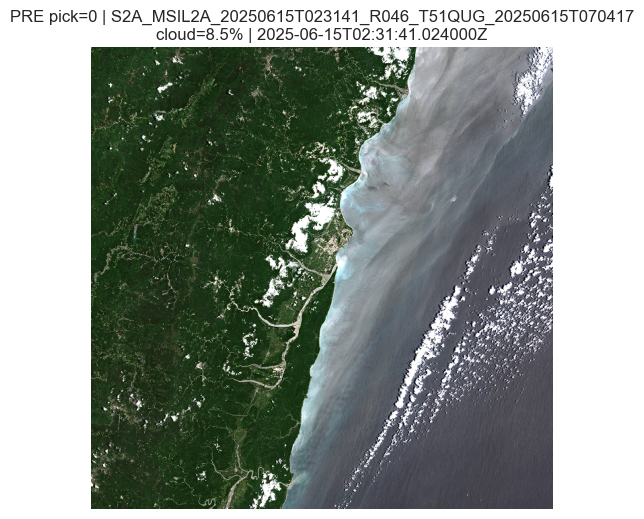

valid_pre shape: (2243, 2474) | valid ratio: 0.9858281815229704


In [4]:
# [S2-demo] Example: find Pre-event candidates and let you choose manually

pre_date = os.getenv("PRE_TARGET_DATE", "2025-06-01")
items_pre = robust_search(stac_client, MATAIAN_BBOX, pre_date, cloud_max=int(os.getenv("S2_CLOUD_MAX", "40")))

print(f"Found {len(items_pre)} candidates for PRE around {pre_date}")
for i, it in enumerate(items_pre[:5]):
    print(f"{i}: {it.id} | cloud={it.properties.get('eo:cloud_cover', 'N/A')} | {it.properties.get('datetime')}")

# 你可以改 index 自己選
pick_idx = 0
pre_item = items_pre[pick_idx]
quicklook_visual(pre_item, title_prefix=f"PRE pick={pick_idx}")

# 先示範怎麼拿 SCL valid mask（後續 Task1 會做 valid_pre/mid/post/intersection）
valid_pre = stream_scl(pre_item, bbox=MATAIAN_BBOX)
print("valid_pre shape:", valid_pre.shape, "| valid ratio:", valid_pre.mean())


Cell 3 - 

Found 1 candidates for MID around 2025-08-15
0: S2B_MSIL2A_20250817T022539_R046_T51QUG_20250817T042827 | cloud=17.585771 | 2025-08-17T02:25:39.024000Z


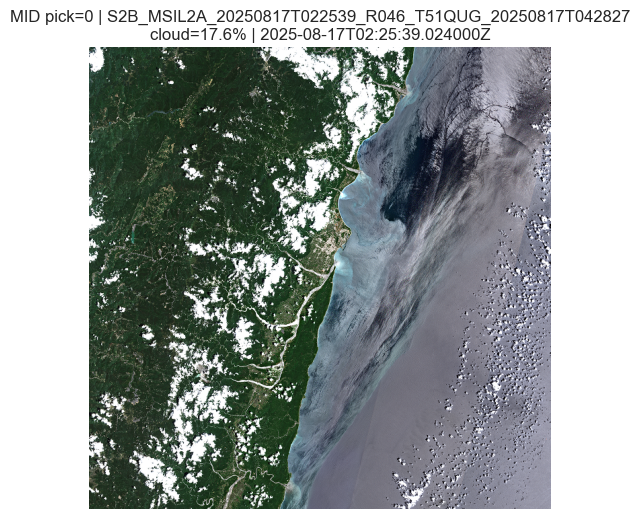

MID_ITEM_ID: S2B_MSIL2A_20250817T022539_R046_T51QUG_20250817T042827
valid_mid shape: (2243, 2474) | valid ratio: 0.7334280980512082


In [5]:
# [S3] ACT 2 ? Mid-event candidates (manual pick + SCL mask)

mid_date = os.getenv("MID_TARGET_DATE", "2025-08-15")
items_mid = robust_search(stac_client, MATAIAN_BBOX, mid_date, cloud_max=int(os.getenv("S2_CLOUD_MAX", "40")))

print(f"Found {len(items_mid)} candidates for MID around {mid_date}")
for i, it in enumerate(items_mid[:5]):
    print(f"{i}: {it.id} | cloud={it.properties.get('eo:cloud_cover', 'N/A')} | {it.properties.get('datetime')}")

if not items_mid:
    raise ValueError(f"No MID scenes found around {mid_date}")

# ???? index ???
pick_idx_mid = 0
mid_item = items_mid[pick_idx_mid]
MID_ITEM_ID = mid_item.id
quicklook_visual(mid_item, title_prefix=f"MID pick={pick_idx_mid}")

valid_mid = stream_scl(mid_item, bbox=MATAIAN_BBOX)
print("MID_ITEM_ID:", MID_ITEM_ID)
print("valid_mid shape:", valid_mid.shape, "| valid ratio:", valid_mid.mean())


Found 4 candidates for POST around 2025-10-10
0: S2B_MSIL2A_20251016T022559_R046_T51QUG_20251016T042804 | cloud=2.543064 | 2025-10-16T02:25:59.024000Z
1: S2B_MSIL2A_20251006T022529_R046_T51QUG_20251006T042653 | cloud=13.276078 | 2025-10-06T02:25:29.024000Z
2: S2C_MSIL2A_20251011T022641_R046_T51QUG_20251011T061121 | cloud=17.947668 | 2025-10-11T02:26:41.025000Z
3: S2A_MSIL2A_20251013T023141_R046_T51QUG_20251013T083919 | cloud=19.312082 | 2025-10-13T02:31:41.024000Z


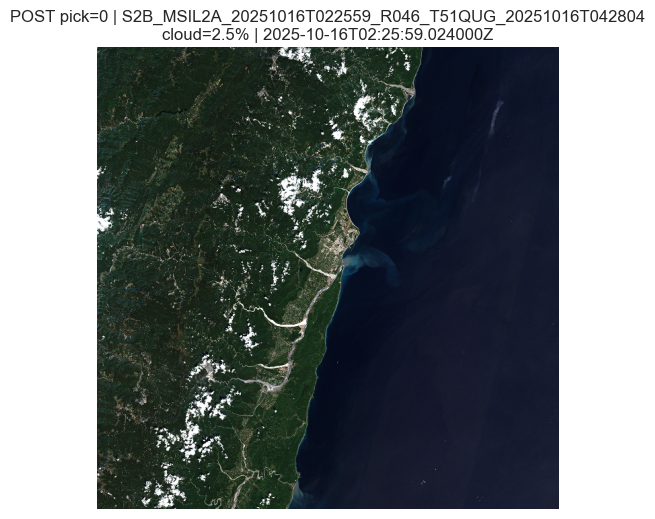

POST_ITEM_ID: S2B_MSIL2A_20251016T022559_R046_T51QUG_20251016T042804
valid_post shape: (2243, 2474) | valid ratio: 0.9109753473575024
valid (intersection) shape: (2243, 2474) | valid ratio: 0.7158283869586545


In [6]:
# [S4] ACT 3 ? Post-event candidates (manual pick + SCL mask)

post_date = os.getenv("POST_TARGET_DATE", "2025-10-10")
items_post = robust_search(stac_client, MATAIAN_BBOX, post_date, cloud_max=int(os.getenv("S2_CLOUD_MAX", "40")))

print(f"Found {len(items_post)} candidates for POST around {post_date}")
for i, it in enumerate(items_post[:5]):
    print(f"{i}: {it.id} | cloud={it.properties.get('eo:cloud_cover', 'N/A')} | {it.properties.get('datetime')}")

if not items_post:
    raise ValueError(f"No POST scenes found around {post_date}")

# ???? index ???
pick_idx_post = 0
post_item = items_post[pick_idx_post]
POST_ITEM_ID = post_item.id
quicklook_visual(post_item, title_prefix=f"POST pick={pick_idx_post}")

valid_post = stream_scl(post_item, bbox=MATAIAN_BBOX)
print("POST_ITEM_ID:", POST_ITEM_ID)
print("valid_post shape:", valid_post.shape, "| valid ratio:", valid_post.mean())

# ??????? mask
if 'valid_pre' in globals() and 'valid_mid' in globals():
    valid = valid_pre & valid_mid & valid_post
    print("valid (intersection) shape:", valid.shape, "| valid ratio:", valid.mean())
else:
    print("Run PRE and MID cells first, then rerun this cell to build 'valid'.")


? SCL masks ready
valid_pre  ratio: 0.986
valid_mid  ratio: 0.733
valid_post ratio: 0.911
valid (intersection) ratio: 0.716


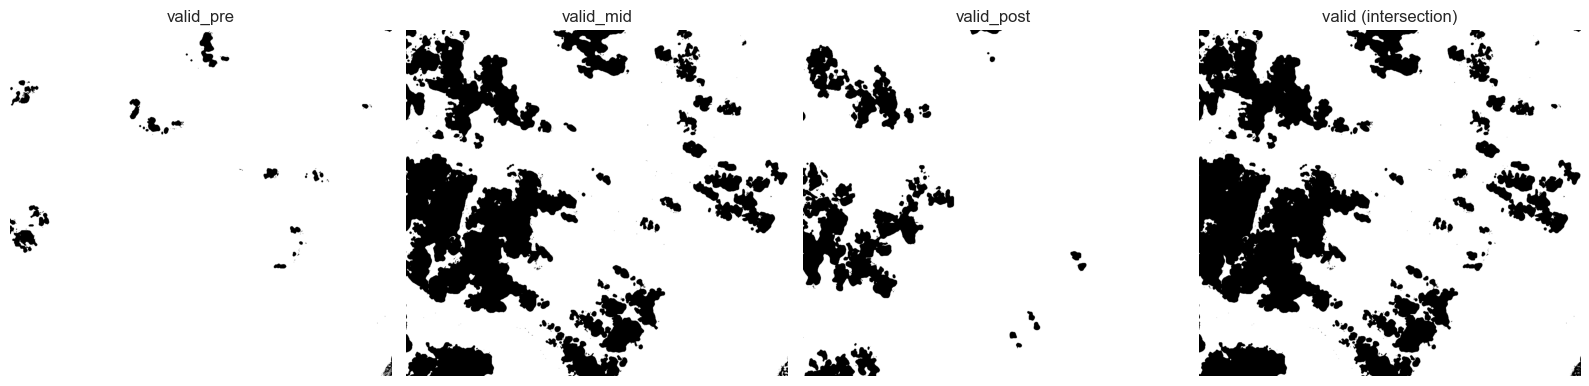

In [10]:
# [S5] Step 1+2 ? SCL cloud masking and intersection valid mask

# Step 1: Build per-scene valid masks (required by HW)
required_items = {
    'pre_item': 'PRE scene item',
    'mid_item': 'MID scene item',
    'post_item': 'POST scene item',
}
for var_name, desc in required_items.items():
    if var_name not in globals():
        raise RuntimeError(f"Missing {desc}: run S2/S3/S4 first.")

valid_pre = stream_scl(pre_item, bbox=MATAIAN_BBOX)
valid_mid = stream_scl(mid_item, bbox=MATAIAN_BBOX)
valid_post = stream_scl(post_item, bbox=MATAIAN_BBOX)

# Step 2: Intersection mask for downstream index differences
valid = valid_pre & valid_mid & valid_post

print('? SCL masks ready')
print(f"valid_pre  ratio: {valid_pre.mean():.3f}")
print(f"valid_mid  ratio: {valid_mid.mean():.3f}")
print(f"valid_post ratio: {valid_post.mean():.3f}")
print(f"valid (intersection) ratio: {valid.mean():.3f}")

# Quick QA visualization
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
axes[0].imshow(valid_pre, cmap='gray')
axes[0].set_title('valid_pre')
axes[1].imshow(valid_mid, cmap='gray')
axes[1].set_title('valid_mid')
axes[2].imshow(valid_post, cmap='gray')
axes[2].set_title('valid_post')
axes[3].imshow(valid, cmap='gray')
axes[3].set_title('valid (intersection)')
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "valid_masks.png"), dpi=300)
plt.show()



In [18]:
# [S6] STAC load: 5-band cubes for Pre/Mid/Post

BANDS = ["B02", "B03", "B04", "B08", "B11"]
BAND_NAMES = {
    "B02": "Blue",
    "B03": "Green",
    "B04": "Red",
    "B08": "NIR",
    "B11": "SWIR",
}
EXPECTED_SHAPE = (2243, 2474, 5)


def stream_cube(scene_item, bands=BANDS, bbox=MATAIAN_BBOX):
    """Load Sentinel-2 multi-band cube as (H, W, C), scaled to reflectance."""
    signed_item = pc.sign(scene_item)
    data = stackstac.stack(
        [signed_item],
        assets=bands,
        epsg=EPSG,
        resolution=RESOLUTION,
        bounds_latlon=bbox,
        chunksize=CHUNKSIZE,
    ).squeeze("time")

    # stackstac output dims: (band, y, x) -> convert to (y, x, band)
    cube = data.transpose("y", "x", "band").compute().values.astype("float32")
    cube = cube / 10000.0
    return cube


required_items = {
    "pre_item": "PRE scene item",
    "mid_item": "MID scene item",
    "post_item": "POST scene item",
}
for var_name, desc in required_items.items():
    if var_name not in globals():
        raise RuntimeError(f"Missing {desc}: run S2/S3/S4 first.")

cubes = {
    "Pre": stream_cube(pre_item),
    "Mid": stream_cube(mid_item),
    "Post": stream_cube(post_item),
}

cube_pre = cubes["Pre"]
cube_mid = cubes["Mid"]
cube_post = cubes["Post"]

for act, cube in cubes.items():
    print(f"{act} cube shape: {cube.shape}")

for act, cube in cubes.items():
    if cube.shape != EXPECTED_SHAPE:
        print(f"[Warning] {act} shape {cube.shape} != expected {EXPECTED_SHAPE}")

print("Bands loaded:", BANDS)
print("Band mapping:", BAND_NAMES)


Pre cube shape: (2243, 2474, 5)
Mid cube shape: (2243, 2474, 5)
Post cube shape: (2243, 2474, 5)
Bands loaded: ['B02', 'B03', 'B04', 'B08', 'B11']
Band mapping: {'B02': 'Blue', 'B03': 'Green', 'B04': 'Red', 'B08': 'NIR', 'B11': 'SWIR'}


In [17]:
# [S7] Compute NDVI / NDWI / BSI and apply intersection mask `valid`

if "cubes" not in globals():
    raise RuntimeError("Missing cubes. Run S6 first.")
if "valid" not in globals():
    raise RuntimeError("Missing intersection mask `valid`. Run S5 first.")

def calc_ndvi(cube):
    red = cube[:, :, 2]   # B04
    nir = cube[:, :, 3]   # B08
    return (nir - red) / (nir + red + 1e-8)

def calc_ndwi(cube):
    green = cube[:, :, 1] # B03
    nir = cube[:, :, 3]   # B08
    return (green - nir) / (green + nir + 1e-8)

def calc_bsi(cube):
    blue = cube[:, :, 0]  # B02
    red = cube[:, :, 2]   # B04
    nir = cube[:, :, 3]   # B08
    swir = cube[:, :, 4]  # B11
    num = (swir + red) - (nir + blue)
    den = (swir + red) + (nir + blue) + 1e-8
    return num / den

indices = {}
for act in ["Pre", "Mid", "Post"]:
    if act not in cubes:
        continue

    ndvi_arr = calc_ndvi(cubes[act]).astype(np.float32)
    ndwi_arr = calc_ndwi(cubes[act]).astype(np.float32)
    bsi_arr = calc_bsi(cubes[act]).astype(np.float32)

    # Assignment requirement: apply intersection mask to all indices
    ndvi_arr = np.where(valid, ndvi_arr, np.nan)
    ndwi_arr = np.where(valid, ndwi_arr, np.nan)
    bsi_arr = np.where(valid, bsi_arr, np.nan)

    indices[act] = {
        "NDVI": ndvi_arr,
        "NDWI": ndwi_arr,
        "BSI": bsi_arr
    }

# Handy aliases
ndvi_pre, ndvi_mid, ndvi_post = indices["Pre"]["NDVI"], indices["Mid"]["NDVI"], indices["Post"]["NDVI"]
ndwi_pre, ndwi_mid, ndwi_post = indices["Pre"]["NDWI"], indices["Mid"]["NDWI"], indices["Post"]["NDWI"]
bsi_pre,  bsi_mid,  bsi_post  = indices["Pre"]["BSI"],  indices["Mid"]["BSI"],  indices["Post"]["BSI"]

# Differences (also keep intersection-valid domain)
dndvi_mid  = np.where(valid, ndvi_mid - ndvi_pre, np.nan)
dndvi_post = np.where(valid, ndvi_post - ndvi_pre, np.nan)

dndwi_mid  = np.where(valid, ndwi_mid - ndwi_pre, np.nan)
dndwi_post = np.where(valid, ndwi_post - ndwi_pre, np.nan)

dbsi_mid   = np.where(valid, bsi_mid - bsi_pre, np.nan)
dbsi_post  = np.where(valid, bsi_post - bsi_pre, np.nan)

print("✓ NDVI / NDWI / BSI computed with intersection mask `valid`")
for act in ["Pre", "Mid", "Post"]:
    print(f"\n{act}:")
    for k in ["NDVI", "NDWI", "BSI"]:
        arr = indices[act][k]
        print(f"  {k}: mean={np.nanmean(arr):.3f}, std={np.nanstd(arr):.3f}, min={np.nanmin(arr):.3f}, max={np.nanmax(arr):.3f}")


✓ NDVI / NDWI / BSI computed with intersection mask `valid`

Pre:
  NDVI: mean=0.519, std=0.165, min=-0.240, max=0.738
  NDWI: mean=-0.457, std=0.145, min=-0.813, max=0.358
  BSI: mean=-0.137, std=0.071, min=-0.360, max=0.758

Mid:
  NDVI: mean=0.504, std=0.189, min=-0.298, max=0.876
  NDWI: mean=-0.444, std=0.167, min=-0.745, max=0.414
  BSI: mean=-0.157, std=0.086, min=-0.388, max=0.569

Post:
  NDVI: mean=0.481, std=0.183, min=-0.228, max=0.782
  NDWI: mean=-0.435, std=0.164, min=-0.699, max=0.342
  BSI: mean=-0.151, std=0.087, min=-0.487, max=0.353


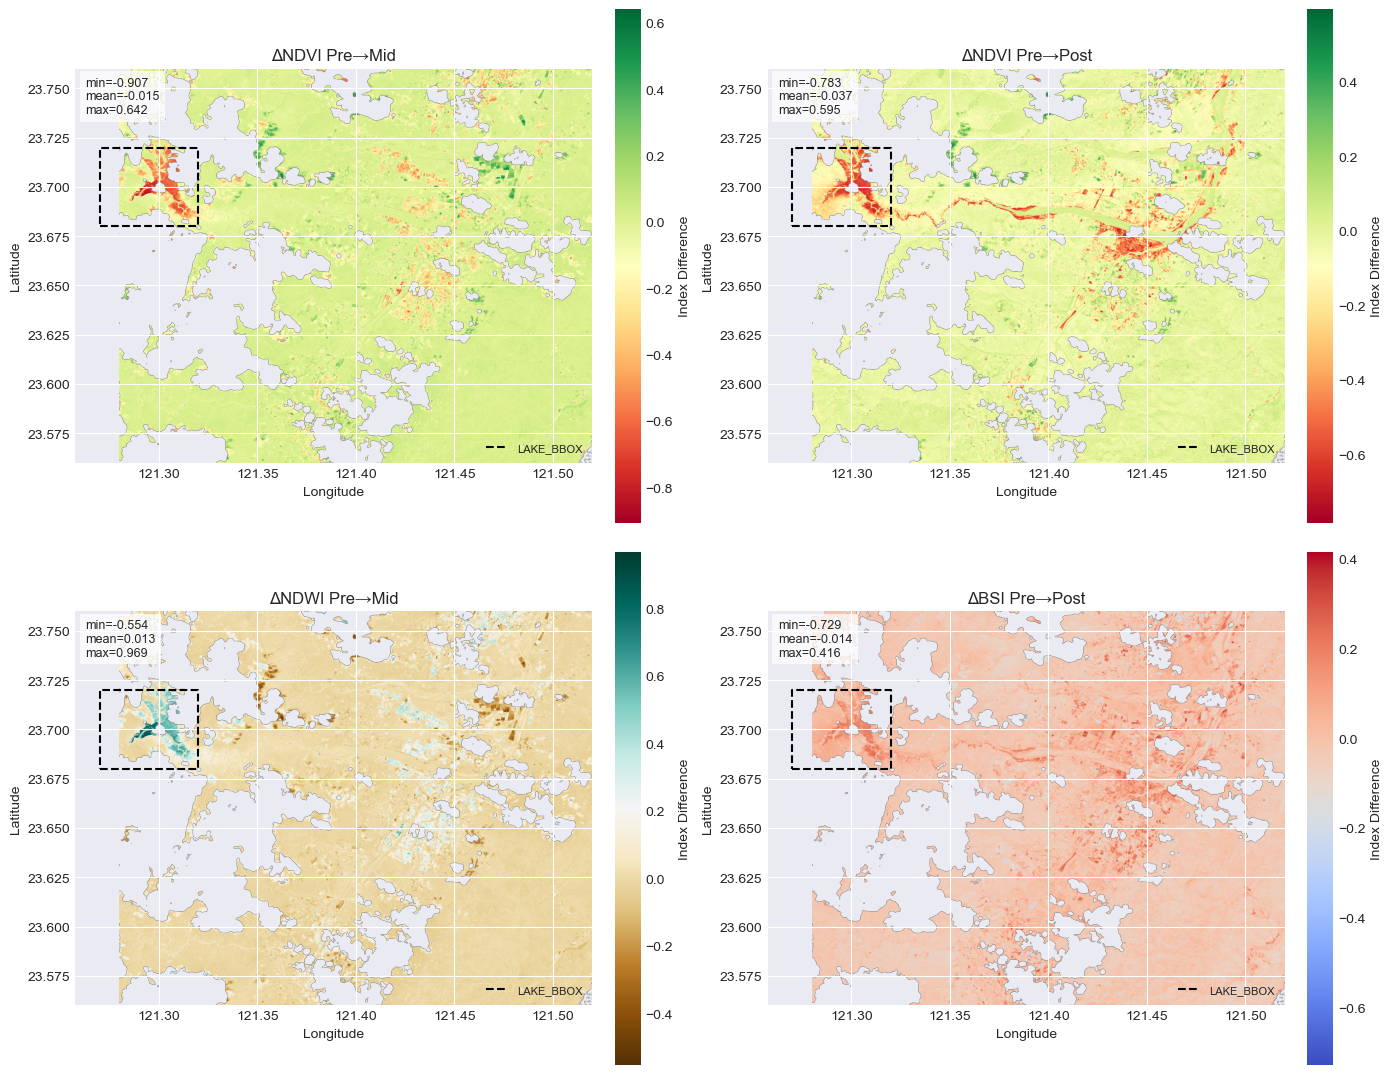

,Layer,min,mean,max
0,ΔNDVI Pre→Mid,-0.9065,-0.0151,0.6422
1,ΔNDVI Pre→Post,-0.7827,-0.0373,0.5947
2,ΔNDWI Pre→Mid,-0.5536,0.0129,0.9689
3,ΔBSI Pre→Post,-0.7289,-0.0142,0.4160


In [16]:
# ---- Visualization (regional context: MATAIAN_BBOX) ----
fig, axes = plt.subplots(2, 2, figsize=(14, 11))

layers = [
    ("ΔNDVI Pre→Mid", dndvi_mid, "RdYlGn"),
    ("ΔNDVI Pre→Post", dndvi_post, "RdYlGn"),
    ("ΔNDWI Pre→Mid", dndwi_mid, "BrBG"),
    ("ΔBSI Pre→Post", dbsi_post, "coolwarm"),
]

stats_rows = []

for ax, (title, arr, cmap) in zip(axes.ravel(), layers):
    arr_min = float(np.nanmin(arr))
    arr_mean = float(np.nanmean(arr))
    arr_max = float(np.nanmax(arr))

    stats_rows.append({
        "Layer": title,
        "min": arr_min,
        "mean": arr_mean,
        "max": arr_max
    })

    im = ax.imshow(
        arr,
        cmap=cmap,
        extent=[MATAIAN_BBOX[0], MATAIAN_BBOX[2], MATAIAN_BBOX[1], MATAIAN_BBOX[3]],
        origin="upper",
    )

    ax.set_title(title)
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")

    # Focused lake bbox
    x0, y0, x1, y1 = LAKE_BBOX_LONLAT
    ax.plot([x0, x1, x1, x0, x0], [y0, y0, y1, y1, y0], "k--", lw=1.5, label="LAKE_BBOX")
    ax.legend(loc="lower right", fontsize=8)

    # Put min/mean/max on each subplot
    stat_text = f"min={arr_min:.3f}\nmean={arr_mean:.3f}\nmax={arr_max:.3f}"
    ax.text(
        0.02, 0.98, stat_text,
        transform=ax.transAxes,
        va="top", ha="left",
        fontsize=9,
        bbox=dict(facecolor="white", alpha=0.75, edgecolor="none")
    )

    cbar = plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    cbar.set_label("Index Difference")

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "difference_maps.png"), dpi=300)
plt.show()

# ---- Stats table (same values as figure annotations) ----
stats_df = pd.DataFrame(stats_rows)
display(stats_df.round(4))


Tassk 2

In [ ]:
# [S9-1] Projection-safe sampling for Task 2 (replace old lonlat_to_rowcol block)

import geopandas as gpd
import pandas as pd
import numpy as np
from rasterio.transform import from_bounds
from rasterio.transform import rowcol

DELTA_NDVI = dndvi_mid if "dndvi_mid" in globals() else dndvi_post
DELTA_NAME = "ΔNDVI Pre→Mid" if "dndvi_mid" in globals() else "ΔNDVI Pre→Post"

# 1) choose validation source
VAL_SOURCE_MODE = "both"  # "teacher" / "mine" / "both"

# Homework asks at least 5 thresholds
THRESHOLDS = np.array([-0.10, -0.20, -0.30, -0.40, -0.50], dtype=np.float32)
teacher_path = "data/validation_points.geojson"
my_path = "data/my_validation_points.geojson"  # if your file is elsewhere, change this line

gdf_teacher = gpd.read_file(teacher_path)
gdf_teacher["val_source"] = "teacher"

if os.path.exists(my_path):
    gdf_my = gpd.read_file(my_path)
    gdf_my["val_source"] = "mine"
else:
    gdf_my = gpd.GeoDataFrame(columns=gdf_teacher.columns, geometry=[], crs=gdf_teacher.crs)

if VAL_SOURCE_MODE == "teacher":
    gdf = gdf_teacher.copy()
elif VAL_SOURCE_MODE == "mine":
    gdf = gdf_my.copy()
elif VAL_SOURCE_MODE == "both":
    gdf = pd.concat([gdf_teacher, gdf_my], ignore_index=True)
    gdf = gpd.GeoDataFrame(gdf, geometry="geometry", crs=gdf_teacher.crs)
else:
    raise ValueError("VAL_SOURCE_MODE must be 'teacher', 'mine', or 'both'.")

if gdf.empty:
    raise RuntimeError("Selected validation set is empty.")

# 2) normalize CRS to EPSG:4326 (lon/lat)
if gdf.crs is None:
    gdf = gdf.set_crs("EPSG:4326", allow_override=True)
else:
    gdf = gdf.to_crs("EPSG:4326")

# 3) keep only LAKE_BBOX points (local accuracy requirement)
xmin, ymin, xmax, ymax = LAKE_BBOX_LONLAT
gdf = gdf.cx[xmin:xmax, ymin:ymax].copy()
if gdf.empty:
    raise RuntimeError("No validation points inside LAKE_BBOX_LONLAT.")

# 4) label parser
def extract_truth_label(row):
    keys = ["truth", "class", "label", "ground_truth_class", "gt", "change"]
    val = None
    for k in keys:
        if k in row and row[k] is not None and str(row[k]).strip() != "":
            val = str(row[k]).strip().lower()
            break
    if val is None:
        return None

    change_tokens = {"1", "y", "yes", "change", "changed", "landslide", "damaged", "impact", "lake", "water"}
    nochange_tokens = {"0", "n", "no", "no_change", "stable", "intact", "unchanged"}

    if val in change_tokens:
        return 1
    if val in nochange_tokens:
        return 0
    return None

# 5) build affine transform from raster bounds (projection-safe pixel lookup)
#    DELTA_NDVI array is drawn with extent=[west,east,south,north], origin='upper'
west, south, east, north = MATAIAN_BBOX
h, w = DELTA_NDVI.shape
transform = from_bounds(west, south, east, north, w, h)

samples = []
for _, r in gdf.iterrows():
    truth = extract_truth_label(r)
    if truth is None:
        continue

    lon, lat = r.geometry.x, r.geometry.y

    # projection-safe map from lon/lat to (row, col)
    rr, cc = rowcol(transform, lon, lat)

    if rr < 0 or rr >= h or cc < 0 or cc >= w:
        continue
    if not valid[rr, cc]:
        continue

    dv = DELTA_NDVI[rr, cc]
    if np.isnan(dv):
        continue

    samples.append((truth, float(dv), lon, lat, r.get("val_source", "unknown")))

if len(samples) == 0:
    raise RuntimeError("No valid sampled points after CRS/mask filtering.")

sample_df = pd.DataFrame(samples, columns=["truth_change", "delta_ndvi", "lon", "lat", "val_source"])
print(f"Using {len(sample_df)} points for threshold sweep ({DELTA_NAME}).")
print(sample_df["val_source"].value_counts())
display(sample_df.head())


Using 35 points for threshold sweep (ΔNDVI Pre→Mid).
val_source
teacher    23
mine       12
Name: count, dtype: int64


,truth_change,delta_ndvi,lon,lat,val_source
0,1,-0.752670,121.290065,23.696969,teacher
1,1,-0.829558,121.289203,23.695774,teacher
2,1,-0.007506,121.292350,23.701141,teacher
3,1,-0.472238,121.292438,23.698934,teacher
4,1,-0.752759,121.291915,23.698659,teacher


In [42]:
# [S9-2] Task 2 threshold sweep table (TP/FP/TN/FN/F1/PA/UA)

def safe_div(a, b):
    return a / b if b > 0 else np.nan

rows = []
for th in THRESHOLDS:
    y_true = sample_df["truth_change"].values.astype(int)
    y_pred = (sample_df["delta_ndvi"].values < th).astype(int)  # change if ΔNDVI < threshold

    tp = int(((y_true == 1) & (y_pred == 1)).sum())
    fp = int(((y_true == 0) & (y_pred == 1)).sum())
    tn = int(((y_true == 0) & (y_pred == 0)).sum())
    fn = int(((y_true == 1) & (y_pred == 0)).sum())

    pa = safe_div(tp, tp + fn)   # Producer's Accuracy
    ua = safe_div(tp, tp + fp)   # User's Accuracy
    f1 = safe_div(2 * pa * ua, pa + ua) if np.isfinite(pa) and np.isfinite(ua) else np.nan

    rows.append({
        "threshold": float(th),
        "TP": tp, "FP": fp, "TN": tn, "FN": fn,
        "F1": f1, "PA": pa, "UA": ua
    })

sweep_df = pd.DataFrame(rows).sort_values("threshold").reset_index(drop=True)
sweep_df.to_csv(os.path.join(OUTPUT_DIR, "threshold_sweep_table.csv"), index=False, encoding="utf-8-sig")
display(sweep_df.round(4))


,threshold,TP,FP,TN,FN,F1,PA,UA
0,-0.5,17,0,6,12,0.7391,0.5862,1.0000
1,-0.4,19,1,5,10,0.7755,0.6552,0.9500
2,-0.3,21,2,4,8,0.8077,0.7241,0.9130
3,-0.2,23,2,4,6,0.8519,0.7931,0.9200
4,-0.1,24,5,1,5,0.8276,0.8276,0.8276


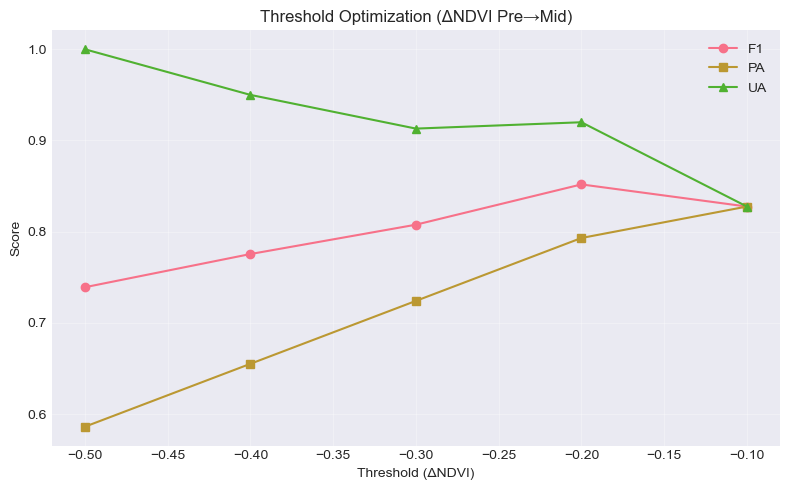

Best threshold is -0.20 with F1 = 0.852 because it gives the highest F1 (PA=0.793, UA=0.920).


In [43]:
# [S9-3] Task 2 plot + best threshold statement

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(sweep_df["threshold"], sweep_df["F1"], marker="o", label="F1")
plt.plot(sweep_df["threshold"], sweep_df["PA"], marker="s", label="PA")
plt.plot(sweep_df["threshold"], sweep_df["UA"], marker="^", label="UA")
plt.xlabel("Threshold (ΔNDVI)")
plt.ylabel("Score")
plt.title(f"Threshold Optimization ({DELTA_NAME})")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "threshold_sweep.png"), dpi=300)
plt.show()

best_idx = sweep_df["F1"].idxmax()
best_row = sweep_df.loc[best_idx]

THRESHOLD_BEST = float(best_row["threshold"])
BEST_F1 = float(best_row["F1"])
BEST_PA = float(best_row["PA"])
BEST_UA = float(best_row["UA"])

print(
    f"Best threshold is {THRESHOLD_BEST:.2f} with F1 = {BEST_F1:.3f} "
    f"because it gives the highest F1 (PA={BEST_PA:.3f}, UA={BEST_UA:.3f})."
)


Task 3

In [44]:
# [S10-1] Task 3 setup: use best threshold and build y_true/y_pred

import numpy as np
import pandas as pd

# Preconditions from Task 2
if "THRESHOLD_BEST" not in globals():
    raise RuntimeError("Missing THRESHOLD_BEST. Run Task 2 first.")
if "sample_df" not in globals():
    raise RuntimeError("Missing sample_df. Run Task 2 sampling cell first.")

# Use sampled validation points from Task 2 (already projection-safe + valid-mask filtered)
df_eval = sample_df.copy()

# Ground truth and prediction
y_true = df_eval["truth_change"].astype(int).values
y_pred = (df_eval["delta_ndvi"].values < THRESHOLD_BEST).astype(int)  # change if ΔNDVI < threshold

print(f"Using threshold: {THRESHOLD_BEST:.3f}")
print(f"Evaluation samples: {len(df_eval)}")
print("Source counts:")
print(df_eval["val_source"].value_counts(dropna=False) if "val_source" in df_eval.columns else "N/A")


Using threshold: -0.200
Evaluation samples: 35
Source counts:
val_source
teacher    23
mine       12
Name: count, dtype: int64


In [45]:
# [S10-2] Task 3 confusion matrix + metrics table

import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

def safe_div(a, b):
    return a / b if b > 0 else np.nan

# Confusion matrix with label order [Change(1), NoChange(0)]
cm = confusion_matrix(y_true, y_pred, labels=[1, 0])

# Mapping:
# rows = actual [change, no-change]
# cols = pred   [change, no-change]
tp = int(cm[0, 0])
fn = int(cm[0, 1])
fp = int(cm[1, 0])
tn = int(cm[1, 1])

total = tp + fp + tn + fn
oa = safe_div(tp + tn, total)
pa = safe_div(tp, tp + fn)   # Producer's Accuracy (recall)
ua = safe_div(tp, tp + fp)   # User's Accuracy (precision)
f1 = safe_div(2 * pa * ua, pa + ua) if np.isfinite(pa) and np.isfinite(ua) else np.nan

# Kappa
row_change = tp + fn
row_nochg = fp + tn
col_change = tp + fp
col_nochg = fn + tn
pe = safe_div((row_change * col_change) + (row_nochg * col_nochg), total * total)
kappa = safe_div(oa - pe, 1 - pe)

# 2x2 table (TP/FP/TN/FN)
cm_table = pd.DataFrame(
    [[tp, fn],
     [fp, tn]],
    index=["Actual Change", "Actual No Change"],
    columns=["Predicted Change", "Predicted No Change"]
)
display(cm_table)

metrics_df = pd.DataFrame([{
    "OA": oa, "PA": pa, "UA": ua, "Kappa": kappa, "F1": f1,
    "TP": tp, "FP": fp, "TN": tn, "FN": fn,
    "Threshold": THRESHOLD_BEST,
    "N_samples": total
}])
display(metrics_df.round(4))


,Predicted Change,Predicted No Change
Actual Change,23,6
Actual No Change,2,4


,OA,PA,UA,Kappa,F1,TP,FP,TN,FN,Threshold,N_samples
0,0.7714,0.7931,0.92,0.3636,0.8519,23,2,4,6,-0.2,35


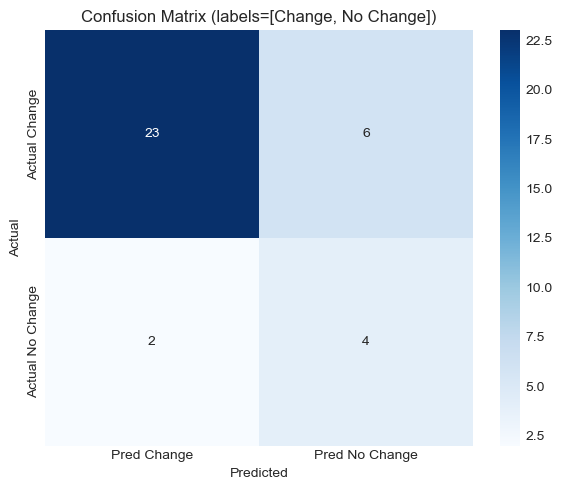

PA=79.3% means we detected 79.3% of actual changes. UA=92.0% means 92.0% of predicted changes were correct.

Bonus comparison (teacher vs mine vs both):


,Source,N,TP,FP,TN,FN,OA,PA,UA,Kappa,F1
0,teacher,23,17,0,0,6,0.7391,0.7391,1.00,0.0000,0.8500
1,mine,12,6,2,4,0,0.8333,1.0000,0.75,0.6667,0.8571
2,both,35,23,2,4,6,0.7714,0.7931,0.92,0.3636,0.8519


In [49]:
# [S10-3] Task 3 heatmap + interpretation + bonus comparison (teacher vs mine vs both)

# Heatmap
plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Pred Change", "Pred No Change"],
    yticklabels=["Actual Change", "Actual No Change"]
)
plt.title("Confusion Matrix (labels=[Change, No Change])")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "confusion_matrix_heatmap.png"), dpi=300)
plt.show()

print(
    f"PA={pa*100:.1f}% means we detected {pa*100:.1f}% of actual changes. "
    f"UA={ua*100:.1f}% means {ua*100:.1f}% of predicted changes were correct."
)

# ---- Bonus comparison by source ----
if "val_source" in df_eval.columns:
    def eval_subset(df_sub, th):
        yt = df_sub["truth_change"].astype(int).values
        yp = (df_sub["delta_ndvi"].values < th).astype(int)

        cm_sub = confusion_matrix(yt, yp, labels=[1, 0])
        tp_ = int(cm_sub[0, 0]); fn_ = int(cm_sub[0, 1]); fp_ = int(cm_sub[1, 0]); tn_ = int(cm_sub[1, 1])
        n_ = tp_ + fn_ + fp_ + tn_

        oa_ = safe_div(tp_ + tn_, n_)
        pa_ = safe_div(tp_, tp_ + fn_)
        ua_ = safe_div(tp_, tp_ + fp_)
        f1_ = safe_div(2 * pa_ * ua_, pa_ + ua_) if np.isfinite(pa_) and np.isfinite(ua_) else np.nan

        row_c = tp_ + fn_; row_n = fp_ + tn_
        col_c = tp_ + fp_; col_n = fn_ + tn_
        pe_ = safe_div((row_c * col_c) + (row_n * col_n), n_ * n_)
        kappa_ = safe_div(oa_ - pe_, 1 - pe_)

        return {
            "TP": tp_, "FP": fp_, "TN": tn_, "FN": fn_, "N": n_,
            "OA": oa_, "PA": pa_, "UA": ua_, "Kappa": kappa_, "F1": f1_
        }

    rows = []
    for src in ["teacher", "mine"]:
        df_src = df_eval[df_eval["val_source"] == src].copy()
        if len(df_src) == 0:
            continue
        r = eval_subset(df_src, THRESHOLD_BEST)
        r["Source"] = src
        rows.append(r)

    r_all = eval_subset(df_eval, THRESHOLD_BEST)
    r_all["Source"] = "both"
    rows.append(r_all)

    compare_df = pd.DataFrame(rows)[["Source","N","TP","FP","TN","FN","OA","PA","UA","Kappa","F1"]]
    compare_df.to_csv(os.path.join(OUTPUT_DIR, "source_comparison_table.csv"), index=False, encoding="utf-8-sig")
    print("\nBonus comparison (teacher vs mine vs both):")
    display(compare_df.round(4))


Task 4

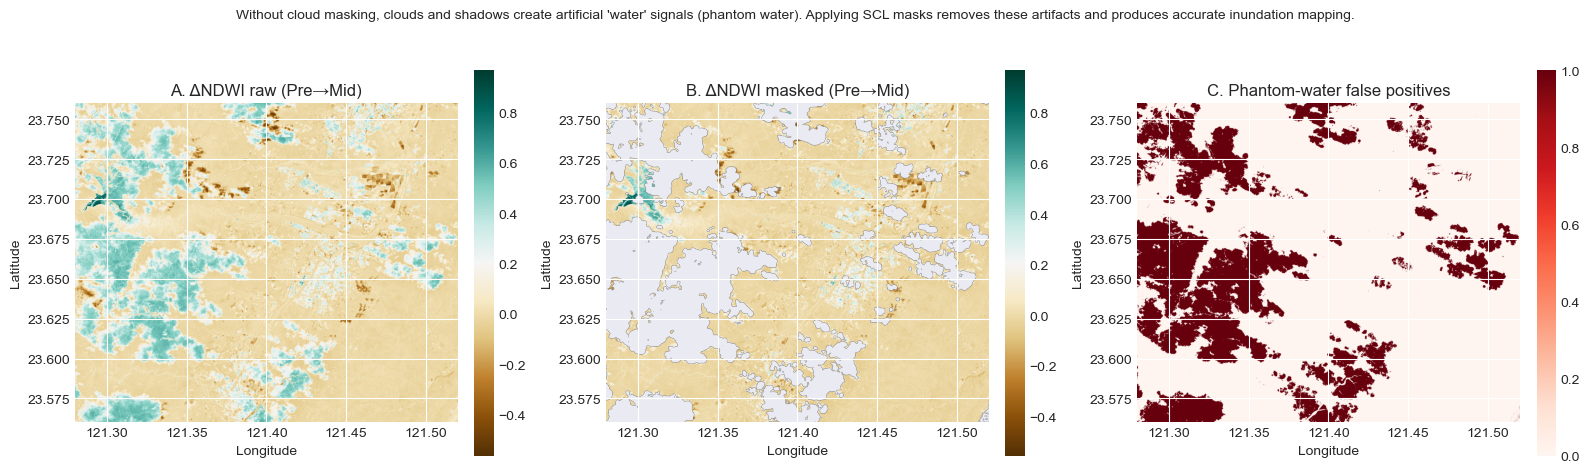

In [51]:
# [S11-1] Phantom Water comparison (A raw NDWI, B masked NDWI, C false positives)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Preconditions
if "cubes" not in globals():
    raise RuntimeError("Missing cubes. Run S6 first.")
if "valid" not in globals():
    raise RuntimeError("Missing intersection mask `valid`. Run S5 first.")

def calc_ndwi(cube):
    green = cube[:, :, 1]  # B03
    nir = cube[:, :, 3]    # B08
    return (green - nir) / (green + nir + 1e-8)

# Choose same period used in threshold task
use_mid = ("DELTA_NAME" in globals() and "Mid" in DELTA_NAME) or ("dndvi_mid" in globals() and "THRESHOLD_BEST" in globals())
if use_mid:
    ndwi_raw_diff = calc_ndwi(cubes["Mid"]).astype(np.float32) - calc_ndwi(cubes["Pre"]).astype(np.float32)
    period_label = "Pre→Mid"
else:
    ndwi_raw_diff = calc_ndwi(cubes["Post"]).astype(np.float32) - calc_ndwi(cubes["Pre"]).astype(np.float32)
    period_label = "Pre→Post"

ndwi_masked_diff = np.where(valid, ndwi_raw_diff, np.nan)

# Phantom-water artifact mask: water-like increase in invalid (cloud/shadow) pixels
PHANTOM_NDWI_THRESHOLD = 0.10
phantom_mask = (ndwi_raw_diff > PHANTOM_NDWI_THRESHOLD) & (~valid)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

im0 = axes[0].imshow(
    ndwi_raw_diff, cmap="BrBG",
    extent=[MATAIAN_BBOX[0], MATAIAN_BBOX[2], MATAIAN_BBOX[1], MATAIAN_BBOX[3]],
    origin="upper"
)
axes[0].set_title(f"A. ΔNDWI raw ({period_label})")
axes[0].set_xlabel("Longitude"); axes[0].set_ylabel("Latitude")
plt.colorbar(im0, ax=axes[0], fraction=0.046, pad=0.04)

im1 = axes[1].imshow(
    ndwi_masked_diff, cmap="BrBG",
    extent=[MATAIAN_BBOX[0], MATAIAN_BBOX[2], MATAIAN_BBOX[1], MATAIAN_BBOX[3]],
    origin="upper"
)
axes[1].set_title(f"B. ΔNDWI masked ({period_label})")
axes[1].set_xlabel("Longitude"); axes[1].set_ylabel("Latitude")
plt.colorbar(im1, ax=axes[1], fraction=0.046, pad=0.04)

im2 = axes[2].imshow(
    phantom_mask.astype(np.uint8), cmap="Reds",
    extent=[MATAIAN_BBOX[0], MATAIAN_BBOX[2], MATAIAN_BBOX[1], MATAIAN_BBOX[3]],
    origin="upper", vmin=0, vmax=1
)
axes[2].set_title("C. Phantom-water false positives")
axes[2].set_xlabel("Longitude"); axes[2].set_ylabel("Latitude")
plt.colorbar(im2, ax=axes[2], fraction=0.046, pad=0.04)

plt.suptitle(
    "Without cloud masking, clouds and shadows create artificial 'water' signals (phantom water). "
    "Applying SCL masks removes these artifacts and produces accurate inundation mapping.",
    fontsize=10
)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "phantom_water_comparison.png"), dpi=300)
plt.show()


In [53]:
# [S11-2] Three-zone confidence classification + area statistics

# Preconditions
if "THRESHOLD_BEST" not in globals():
    raise RuntimeError("Missing THRESHOLD_BEST from Task 2.")
if "valid" not in globals():
    raise RuntimeError("Missing valid mask from Task 1.")

# Use same ΔNDVI period as Task 2
if "DELTA_NAME" in globals() and "Mid" in DELTA_NAME:
    delta_ndvi_eval = dndvi_mid
    period_label = "Pre→Mid"
else:
    delta_ndvi_eval = dndvi_post
    period_label = "Pre→Post"

# Important: threshold is negative in ΔNDVI logic; use absolute magnitude for confidence zoning
t = abs(float(THRESHOLD_BEST))
t_high = 1.5 * t
abs_d = np.abs(delta_ndvi_eval)

# zone_map:
# 0 = invalid/not analyzed
# 1 = high confidence
# 2 = low confidence
# 3 = no detection
zone_map = np.zeros_like(abs_d, dtype=np.uint8)
zone_map[(valid) & (abs_d > t_high)] = 1
zone_map[(valid) & (abs_d > t) & (abs_d <= t_high)] = 2
zone_map[(valid) & (abs_d <= t)] = 3

# Area stats (km²)
pixel_area_m2 = float(RESOLUTION) * float(RESOLUTION)  # 10m * 10m = 100 m²
to_km2 = pixel_area_m2 / 1_000_000.0

high_km2 = (zone_map == 1).sum() * to_km2
low_km2 = (zone_map == 2).sum() * to_km2
none_km2 = (zone_map == 3).sum() * to_km2
analyzed_km2 = valid.sum() * to_km2
total_study_km2 = zone_map.size * to_km2

zone_stats_df = pd.DataFrame([
    {"Zone": "High Confidence", "Area_km2": high_km2},
    {"Zone": "Low Confidence", "Area_km2": low_km2},
    {"Zone": "No Detection", "Area_km2": none_km2},
    {"Zone": "Analyzed (valid intersection)", "Area_km2": analyzed_km2},
    {"Zone": "Total Study Area (full bbox)", "Area_km2": total_study_km2},
])
zone_stats_df.to_csv(os.path.join(OUTPUT_DIR, "confidence_zone_stats.csv"), index=False, encoding="utf-8-sig") 
display(zone_stats_df.round(4))
print(f"Threshold magnitude |T|={t:.3f}, High boundary={t_high:.3f} ({period_label})")
print(f"High confidence zones cover {high_km2:.3f} km², representing the core impact area.")


,Zone,Area_km2
0,High Confidence,15.1862
1,Low Confidence,13.7616
2,No Detection,368.2781
3,Analyzed (valid intersection),397.2262
4,Total Study Area (full bbox),554.9182


Threshold magnitude |T|=0.200, High boundary=0.300 (Pre→Mid)
High confidence zones cover 15.186 km², representing the core impact area.


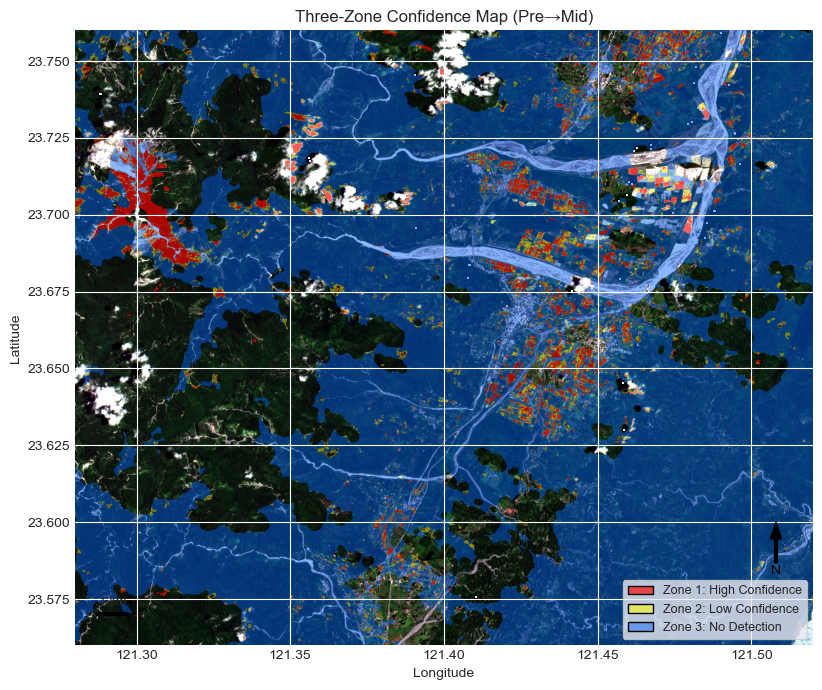

In [55]:
# [S11-3] Confidence map with legend + north arrow + scale bar (overlay on RGB base)

from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

# Build simple RGB base from Pre scene
def rgb_stretch(cube, q=(2, 98)):
    rgb = cube[:, :, [2, 1, 0]].copy()  # R,G,B = B04,B03,B02
    out = np.zeros_like(rgb, dtype=np.float32)
    for i in range(3):
        lo, hi = np.nanpercentile(rgb[:, :, i], q[0]), np.nanpercentile(rgb[:, :, i], q[1])
        out[:, :, i] = np.clip((rgb[:, :, i] - lo) / (hi - lo + 1e-8), 0, 1)
    return out

def add_north_arrow(ax, x=0.95, y=0.12):
    ax.annotate(
        "N", xy=(x, y + 0.08), xytext=(x, y),
        xycoords="axes fraction", textcoords="axes fraction",
        arrowprops=dict(facecolor="black", width=2, headwidth=8),
        ha="center", va="center", fontsize=10, color="black"
    )

def add_scale_bar_km(ax, bbox, km=1.0):
    west, south, east, north = bbox
    lat0 = (south + north) / 2.0
    km_per_deg_lon = 111.32 * np.cos(np.deg2rad(lat0))
    dlon = km / km_per_deg_lon

    x0 = west + 0.03 * (east - west)
    y0 = south + 0.05 * (north - south)
    x1 = x0 + dlon
    ax.plot([x0, x1], [y0, y0], color="black", lw=3)
    ax.text((x0 + x1) / 2, y0 + 0.01 * (north - south), f"{km:g} km", ha="center", va="bottom", fontsize=9)

rgb_base = rgb_stretch(cubes["Pre"])

# zone_map colors: 0 invalid transparent-ish, 1 high(red), 2 low(yellow), 3 none(blue)
cmap_zone = ListedColormap([
    (0, 0, 0, 0.00),    # 0 invalid
    (1, 0, 0, 0.65),    # 1 high
    (1, 1, 0, 0.55),    # 2 low
    (0, 0.4, 1, 0.45),  # 3 none
])

fig, ax = plt.subplots(figsize=(9, 7))
ax.imshow(
    rgb_base,
    extent=[MATAIAN_BBOX[0], MATAIAN_BBOX[2], MATAIAN_BBOX[1], MATAIAN_BBOX[3]],
    origin="upper"
)
ax.imshow(
    zone_map,
    cmap=cmap_zone, vmin=0, vmax=3,
    extent=[MATAIAN_BBOX[0], MATAIAN_BBOX[2], MATAIAN_BBOX[1], MATAIAN_BBOX[3]],
    origin="upper"
)

ax.set_title(f"Three-Zone Confidence Map ({period_label})")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")

legend_elements = [
    Patch(facecolor=(1,0,0,0.65), edgecolor="k", label="Zone 1: High Confidence"),
    Patch(facecolor=(1,1,0,0.55), edgecolor="k", label="Zone 2: Low Confidence"),
    Patch(facecolor=(0,0.4,1,0.45), edgecolor="k", label="Zone 3: No Detection"),
]
ax.legend(handles=legend_elements, loc="lower right", fontsize=9, frameon=True)

add_north_arrow(ax)
add_scale_bar_km(ax, MATAIAN_BBOX, km=1.0)

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "confidence_map_overlay.png"), dpi=300)
plt.show()


Task 5

## 6. AI Advisor Input

### Prompt
Given these accuracy metrics from remote sensing validation of a barrier lake disaster, what confidence level would you assign to operational decisions? What additional data would improve confidence?

- OA: **[0.7714]%**
- PA: **[0.7931]%**
- UA: **[0.92]%**
- Kappa: **[0.3636]**
- High confidence area: **[15.1862] km²**
- Threshold: **[-0.2]**

Please provide:
1. An operational confidence rating (High / Moderate / Low) and why  
2. Whether immediate action is justified in high-confidence zones  
3. What additional data would most improve confidence in low-confidence zones

---

### LLM Response
Based on the provided validation metrics, I would assign a **[High/Moderate/Low] operational confidence** level.

- **Why:** OA and Kappa indicate overall agreement quality, while PA and UA provide class-specific reliability.  
- If **PA is high**, the system is effectively capturing true impact areas (low omission).  
- If **UA is high**, most predicted impacts are likely true (low commission).  
- With a mapped high-confidence area of **[15.1862] km²**, immediate prioritization of that zone is justified, especially if consequences of missed detection are high.

**Operational recommendation:**
- **High-confidence zones:** Immediate field verification / precautionary action is justified.  
- **Low-confidence zones:** Treat as watch areas; re-evaluate with the next clear-sky acquisition and local checks.

**Additional data to improve confidence:**
1. Higher temporal frequency optical imagery to reduce timing mismatch  
2. SAR data (e.g., Sentinel-1) for cloud-robust water and deformation signals  
3. DEM/slope and hydrologic context for terrain-consistent screening  
4. Additional independent ground truth points in boundary/mixed pixels  
5. Event-synchronized field observations (waterline, debris, channel blockage)

---

### My Reflection
The LLM highlights that decision confidence should not rely on OA alone, and that **PA/UA balance is critical** for operational use. This aligns with my Task 2 threshold optimization and Task 3 confusion-matrix interpretation, where I selected a threshold that balanced omission and commission errors instead of maximizing only one side.

I agree with the recommendation to prioritize **high-confidence zones** for immediate action and to treat low-confidence zones as revalidation targets. This is consistent with my Task 4 three-zone map, where the high-confidence area represents the core impact footprint.

The suggestion to add **SAR and more independent validation points** is especially relevant. Optical indices remain vulnerable to cloud timing and mixed-pixel uncertainty, so multi-sensor integration would likely improve robustness in future assessments.


## 7. Week 8 vs. Week 9 Comparison

| Layer | W8 Finding | W9 Validated Finding | Agreement | Notes |
|-------|-----------|----------------------|-----------|-------|
| Vegetation Impact | Damaged in upper basin | High-confidence change in core zone; low-confidence at boundary | Y | W9 confirms core vegetation loss; boundary remains uncertain |
| Water Inundation | Expanded lake area | NDWI increase + masked map confirms inundation in lake zone | Y | Cloud masking removed phantom water and improved confidence |
| Debris Field | Possible debris spread (?) | BSI increase in selected slope/valley pixels, mostly low-confidence | N | W8 likely overstated debris extent from visual texture alone |

Validation mostly confirms Week 8 interpretation in the core impact area, especially for vegetation loss and inundation.
Uncertainty appears at transition zones where confidence is low and where PA/UA trade-offs indicate omission/commission risk.
Week 8 likely overstated some boundary debris signals that were not strongly supported after masking and threshold validation.
Overall, Week 9 increased confidence in the mapped disaster extent by converting visual judgment into validated metrics.
